# K nearest neighbours (KNN) implementado a mano

**Notebook compatible con Google Colab · Clasificación · Python 3**

Implementaremos KNN sin `KNeighborsClassifier`, funciones de distancias ni métricas de evaluación de bibliotecas. La búsqueda será exhaustiva: calcularemos la distancia a cada ejemplo de entrenamiento y ordenaremos los resultados.

Admitiremos tres distancias: **euclidiana**, **Manhattan** y **suma de ambas**. Usaremos `make_blobs` de scikit-learn exclusivamente para generar datos. NumPy y Matplotlib servirán para preparar las gráficas; el algoritmo trabajará con listas y funciones de Python.

**Cómo ejecutarlo en Colab:** sube este archivo desde **Archivo → Subir notebook** y selecciona **Entorno de ejecución → Ejecutar todas**. No requiere GPU, archivos externos ni acceso a Drive.


In [1]:
import math
import random
from numbers import Integral

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_blobs

SEMILLA = 42
METRICAS = ("euclidiana", "manhattan", "suma")
COLORES = ListedColormap(["#3366CC", "#E67E22", "#26946A"])
print("Importaciones listas. Semilla:", SEMILLA)


Importaciones listas. Semilla: 42


Colab ya incluye estas dependencias. Si ejecutas el notebook en otro entorno y falta alguna, ejecuta la siguiente celda después de quitar el comentario y vuelve a ejecutar las importaciones.


In [2]:
# %pip install scikit-learn numpy matplotlib


## 1. Cómo decide KNN

Para clasificar un punto nuevo:

1. Calcula su distancia a **todos** los puntos de entrenamiento.
2. Ordena esos puntos desde el más cercano hasta el más lejano.
3. Toma los primeros $k$ vecinos.
4. Devuelve la clase que obtiene más votos. Todos los vecinos valen un voto.

KNN conserva los datos durante `fit`; el trabajo principal ocurre al predecir. Usaremos $k=5$ como ejemplo, pero la clase admite cualquier entero entre 1 y el número de ejemplos de entrenamiento.

**Empates:** si varias clases tienen los mismos votos, gana la que tiene el vecino más cercano entre ellas. Si dos vecinos están a la misma distancia, se respeta su orden en los datos de entrenamiento. Un $k$ impar no elimina todos los empates cuando hay más de dos clases.


## 2. Las tres distancias

Para dos vectores $a,b\in\mathbb{R}^{p}$:

$$d_E(a,b)=\sqrt{\sum_{j=1}^{p}(a_j-b_j)^2}$$

$$d_M(a,b)=\sum_{j=1}^{p}|a_j-b_j|$$

$$d_S(a,b)=d_E(a,b)+d_M(a,b)$$

Aquí **suma** significa sumar las dos distancias completas, sin pesos ni normalización. Es una distancia válida: hereda, entre otras propiedades, la desigualdad triangular de sus dos componentes. No equivale en general a la distancia euclidiana ni a Manhattan y puede cambiar el orden de los vecinos.

Por ejemplo, entre $(0,0)$ y $(3,4)$, los resultados son $5$, $7$ y $12$, respectivamente.


In [3]:
def distancia_euclidiana(a, b):
    if len(a) != len(b):
        raise ValueError("Los vectores deben tener la misma dimensión.")
    suma_cuadrados = 0.0
    for j in range(len(a)):
        suma_cuadrados += (a[j] - b[j]) ** 2
    return math.sqrt(suma_cuadrados)


def distancia_manhattan(a, b):
    if len(a) != len(b):
        raise ValueError("Los vectores deben tener la misma dimensión.")
    suma_absolutos = 0.0
    for j in range(len(a)):
        suma_absolutos += abs(a[j] - b[j])
    return suma_absolutos


def distancia_suma(a, b):
    return distancia_euclidiana(a, b) + distancia_manhattan(a, b)


DISTANCIAS = {
    "euclidiana": distancia_euclidiana,
    "manhattan": distancia_manhattan,
    "suma": distancia_suma,
}

for nombre, funcion in DISTANCIAS.items():
    print(f"{nombre:12s}: {funcion([0, 0], [3, 4]):.1f}")


euclidiana  : 5.0
manhattan   : 7.0
suma        : 12.0


## 3. Clasificador a mano

`fit(X, y)` guarda una copia de los ejemplos y sus etiquetas. `vecinos(x)` expone los $k$ vecinos de un punto como tuplas `(distancia, índice de entrenamiento, clase)`. `predict(X)` aplica la votación a cada punto.

Usamos `sorted` para ordenar los valores que calculamos nosotros. No usamos árboles de búsqueda, funciones de distancia de NumPy o SciPy, ni implementaciones de KNN de bibliotecas. Las etiquetas deben ser utilizables como claves de un diccionario, por ejemplo enteros o cadenas.


In [4]:
class KNNManual:
    def __init__(self, k=5, metrica="euclidiana"):
        if isinstance(k, bool) or not isinstance(k, Integral) or k < 1:
            raise ValueError("k debe ser un entero positivo.")
        if metrica not in DISTANCIAS:
            raise ValueError(f"Métrica desconocida. Usa una de: {tuple(DISTANCIAS)}")
        self.k = int(k)
        self.metrica = metrica
        self._distancia = DISTANCIAS[metrica]
        self._X = None
        self._y = None
        self._dimension = None

    @staticmethod
    def _convertir_vector(vector):
        try:
            resultado = [float(valor) for valor in vector]
        except (TypeError, ValueError) as error:
            raise ValueError("Cada ejemplo debe ser un vector numérico.") from error
        if not resultado or not all(math.isfinite(valor) for valor in resultado):
            raise ValueError("Los vectores deben ser no vacíos y contener valores finitos.")
        return resultado

    def fit(self, X, y):
        ejemplos = [self._convertir_vector(fila) for fila in X]
        etiquetas = list(y)
        if not ejemplos or len(ejemplos) != len(etiquetas):
            raise ValueError("X e y deben tener la misma longitud y no estar vacíos.")
        dimension = len(ejemplos[0])
        if any(len(fila) != dimension for fila in ejemplos):
            raise ValueError("Todos los ejemplos deben tener la misma dimensión.")
        if self.k > len(ejemplos):
            raise ValueError("k no puede superar el número de ejemplos de entrenamiento.")
        for etiqueta in etiquetas:
            try:
                hash(etiqueta)
            except TypeError as error:
                raise ValueError("Las etiquetas deben poder usarse como claves.") from error
        self._X = ejemplos
        self._y = etiquetas
        self._dimension = dimension
        return self

    def vecinos(self, x):
        if self._X is None:
            raise ValueError("Primero debes entrenar el modelo con fit.")
        punto = self._convertir_vector(x)
        if len(punto) != self._dimension:
            raise ValueError("El punto debe tener la misma dimensión que el entrenamiento.")

        distancias = []
        for indice, ejemplo in enumerate(self._X):
            distancia = self._distancia(punto, ejemplo)
            distancias.append((distancia, indice, self._y[indice]))

        ordenadas = sorted(distancias, key=lambda vecino: (vecino[0], vecino[1]))
        return ordenadas[:self.k]

    @staticmethod
    def _votar(vecinos):
        votos = {}
        # La inserción sigue el orden de cercanía de los vecinos.
        for distancia, indice, clase in vecinos:
            votos[clase] = votos.get(clase, 0) + 1
        # max conserva la primera clave encontrada cuando los votos empatan.
        return max(votos, key=votos.get)

    def predict(self, X):
        if self._X is None:
            raise ValueError("Primero debes entrenar el modelo con fit.")
        predicciones = []
        for punto in X:
            predicciones.append(self._votar(self.vecinos(punto)))
        return predicciones


## 4. Comprobaciones con resultados conocidos

Antes de usar datos aleatorios, verificamos las distancias, la votación, el desempate y errores habituales. También comprobamos un ejemplo donde euclidiana y Manhattan eligen vecinos distintos: desde el origen, $(2,2)$ está más cerca según euclidiana, pero $(3,0)$ está más cerca según Manhattan y la suma.


In [5]:
assert math.isclose(distancia_euclidiana([0, 0], [3, 4]), 5)
assert math.isclose(distancia_manhattan([0, 0], [3, 4]), 7)
assert math.isclose(distancia_suma([0, 0], [3, 4]), 12)
for funcion in DISTANCIAS.values():
    assert funcion([2, -1], [2, -1]) == 0
    assert funcion([2, -1], [-3, 4]) == funcion([-3, 4], [2, -1])

X_pequeno = [[0, 0], [0, 1], [4, 4], [4, 5]]
y_pequeno = ["A", "A", "B", "B"]
for metrica in METRICAS:
    modelo_prueba = KNNManual(k=3, metrica=metrica).fit(X_pequeno, y_pequeno)
    assert modelo_prueba.predict([[0, 0.2], [4, 4.2]]) == ["A", "B"]
    assert modelo_prueba.predict([]) == []

# Empate en votos: gana B porque su vecino está más cerca.
modelo_empate = KNNManual(k=2).fit([[0], [3]], ["A", "B"])
assert modelo_empate.predict([[2]]) == ["B"]
# Empate también en distancia: gana la primera etiqueta en el entrenamiento.
assert modelo_empate.predict([[1.5]]) == ["A"]

X_orden = [[3, 0], [2, 2]]
y_orden = ["sobre el eje", "diagonal"]
assert KNNManual(1, "euclidiana").fit(X_orden, y_orden).predict([[0, 0]]) == ["diagonal"]
assert KNNManual(1, "manhattan").fit(X_orden, y_orden).predict([[0, 0]]) == ["sobre el eje"]
assert KNNManual(1, "suma").fit(X_orden, y_orden).predict([[0, 0]]) == ["sobre el eje"]


def debe_fallar(operacion):
    try:
        operacion()
    except ValueError:
        return
    raise AssertionError("Se esperaba un ValueError.")


debe_fallar(lambda: KNNManual(k=0))
debe_fallar(lambda: KNNManual(k=1.5))
debe_fallar(lambda: KNNManual(metrica="otra"))
debe_fallar(lambda: KNNManual().predict([[0, 0]]))
debe_fallar(lambda: KNNManual(k=5).fit(X_pequeno, y_pequeno))
debe_fallar(lambda: KNNManual(k=1).fit([], []))
debe_fallar(lambda: KNNManual(k=1).fit([[0], [1, 2]], [0, 1]))
debe_fallar(lambda: KNNManual(k=1).fit([[0]], []))
debe_fallar(lambda: KNNManual(k=1).fit([[float("nan")]], [0]))
debe_fallar(lambda: modelo_empate.predict([[0, 1]]))
debe_fallar(lambda: distancia_euclidiana([1], [1, 2]))
print("Todas las comprobaciones pasaron.")


Todas las comprobaciones pasaron.


## 5. Tres conjuntos de datos con `make_blobs`

Generamos tres problemas de clasificación con dos características y tres clases:

- **Separados:** grupos compactos y fáciles de distinguir.
- **Solapados:** mayor dispersión; algunas clases se superponen.
- **Alargados:** transformamos linealmente los puntos generados con `make_blobs` para obtener grupos con otra geometría.

La semilla permite repetir el experimento. La transformación del tercer conjunto también está escrita explícitamente.


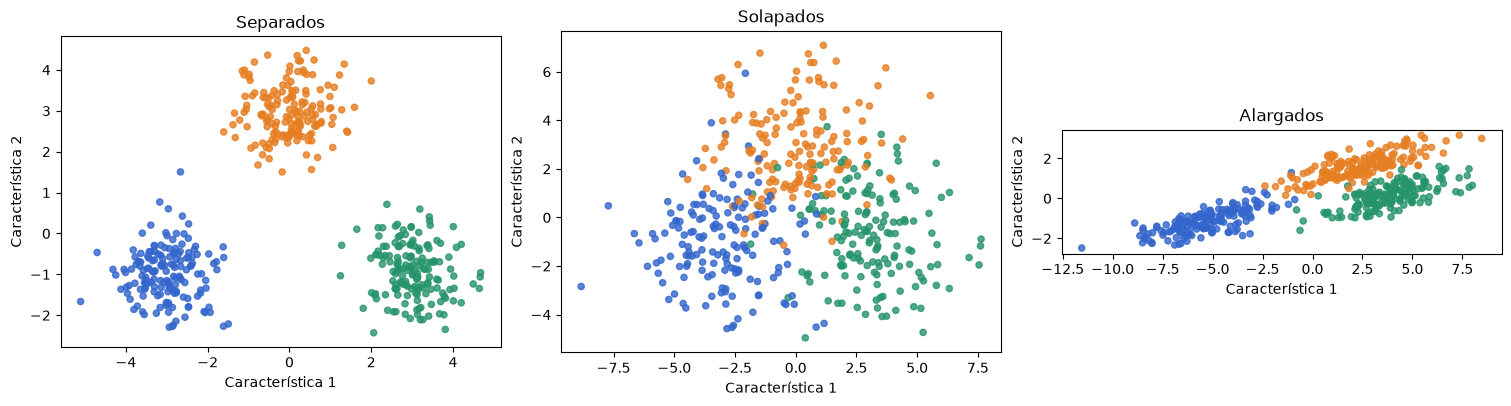

In [6]:
CENTROS = [(-3, -1), (0, 3), (3, -1)]
conjuntos = {}

for nombre, dispersion in [("Separados", 0.65), ("Solapados", 1.8), ("Alargados", 1.1)]:
    X_array, y_array = make_blobs(
        n_samples=480,
        n_features=2,
        centers=CENTROS,
        cluster_std=dispersion,
        random_state=SEMILLA,
    )
    X = X_array.tolist()
    y = y_array.tolist()
    if nombre == "Alargados":
        X = [[1.5 * x1 + 0.8 * x2, 0.2 * x1 + 0.55 * x2] for x1, x2 in X]
    conjuntos[nombre] = (X, y)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for eje, (nombre, (X, y)) in zip(ejes, conjuntos.items()):
    eje.scatter([p[0] for p in X], [p[1] for p in X], c=y,
                cmap=COLORES, vmin=-0.5, vmax=2.5, s=20, alpha=0.8)
    eje.set(title=nombre, xlabel="Característica 1", ylabel="Característica 2")
    eje.set_aspect("equal", adjustable="box")
plt.show()


## 6. Separación y evaluación a mano

Reservamos el **30 %** de cada conjunto para prueba. La separación mezcla índices con `random.Random`, sin `train_test_split`. Cada distancia recibe exactamente los mismos datos de entrenamiento y prueba. Esta separación es aleatoria, no estratificada.

La **exactitud** es la proporción de predicciones correctas. La **matriz de confusión** cuenta, por fila, la clase real y, por columna, la clase predicha. No usamos `accuracy_score` ni `confusion_matrix`.


In [7]:
def separar_datos(X, y, proporcion_prueba=0.3, semilla=42):
    if len(X) != len(y) or len(X) < 2:
        raise ValueError("Se requieren al menos dos ejemplos con sus etiquetas.")
    if not 0 < proporcion_prueba < 1:
        raise ValueError("La proporción de prueba debe estar entre 0 y 1.")
    indices = list(range(len(X)))
    random.Random(semilla).shuffle(indices)
    n_prueba = max(1, min(len(X) - 1, int(len(X) * proporcion_prueba)))
    indices_prueba = indices[:n_prueba]
    indices_entrenamiento = indices[n_prueba:]
    return (
        [X[i] for i in indices_entrenamiento],
        [X[i] for i in indices_prueba],
        [y[i] for i in indices_entrenamiento],
        [y[i] for i in indices_prueba],
    )


def exactitud(y_real, y_predicha):
    if not y_real or len(y_real) != len(y_predicha):
        raise ValueError("Las etiquetas deben tener igual longitud y no estar vacías.")
    aciertos = 0
    for real, predicha in zip(y_real, y_predicha):
        if real == predicha:
            aciertos += 1
    return aciertos / len(y_real)


def matriz_confusion_manual(y_real, y_predicha, clases):
    if not y_real or len(y_real) != len(y_predicha):
        raise ValueError("Las etiquetas deben tener igual longitud y no estar vacías.")
    posiciones = {clase: i for i, clase in enumerate(clases)}
    matriz = [[0 for _ in clases] for _ in clases]
    for real, predicha in zip(y_real, y_predicha):
        matriz[posiciones[real]][posiciones[predicha]] += 1
    return matriz


# Verificación con un ejemplo calculable a mano.
assert exactitud([0, 1, 1, 2], [0, 0, 1, 2]) == 0.75
assert matriz_confusion_manual([0, 1, 1, 2], [0, 0, 1, 2], [0, 1, 2]) == [
    [1, 0, 0], [1, 1, 0], [0, 0, 1]
]
particiones = {nombre: separar_datos(X, y, semilla=SEMILLA)
               for nombre, (X, y) in conjuntos.items()}
assert particiones == {nombre: separar_datos(X, y, semilla=SEMILLA)
                       for nombre, (X, y) in conjuntos.items()}
for nombre, (X_train, X_test, y_train, y_test) in particiones.items():
    print(f"{nombre:12s}: {len(X_train)} entrenamiento / {len(X_test)} prueba")


Separados   : 336 entrenamiento / 144 prueba
Solapados   : 336 entrenamiento / 144 prueba
Alargados   : 336 entrenamiento / 144 prueba


## 7. Comparar las tres distancias

Fijamos $k=5$ **antes** de evaluar. La tabla y las matrices describen esta separación concreta; no establecen que una distancia sea siempre superior. Para elegir $k$ o una distancia con fines de uso real, utiliza un conjunto de validación o validación cruzada dentro del entrenamiento y reserva la prueba para la evaluación final.


Conjunto       Distancia       Exactitud
----------------------------------------
Separados      euclidiana       100.00%
Separados      manhattan        100.00%
Separados      suma             100.00%
Solapados      euclidiana        86.81%
Solapados      manhattan         86.11%
Solapados      suma              86.81%
Alargados      euclidiana        99.31%
Alargados      manhattan         98.61%
Alargados      suma              99.31%


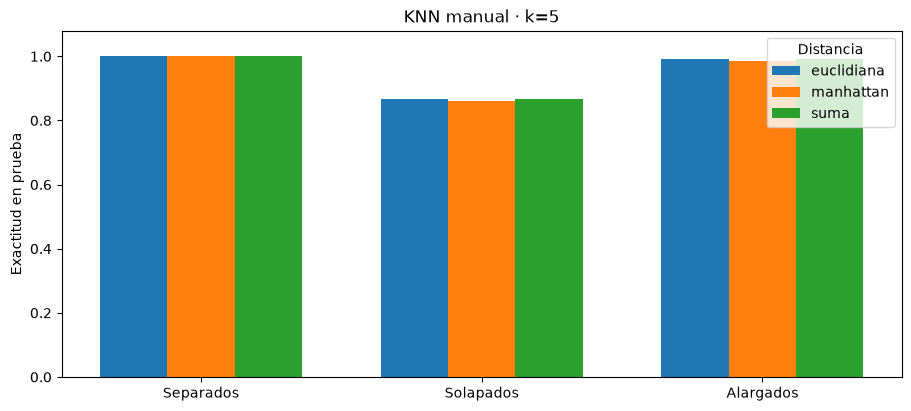

In [8]:
K = 5
resultados = []
modelos = {}
predicciones = {}

for nombre, (X_train, X_test, y_train, y_test) in particiones.items():
    for metrica in METRICAS:
        modelo = KNNManual(k=K, metrica=metrica).fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
        modelos[(nombre, metrica)] = modelo
        predicciones[(nombre, metrica)] = y_pred
        resultados.append((nombre, metrica, exactitud(y_test, y_pred)))

print(f"{'Conjunto':<14} {'Distancia':<14} {'Exactitud':>10}")
print("-" * 40)
for nombre, metrica, puntuacion in resultados:
    print(f"{nombre:<14} {metrica:<14} {puntuacion:>9.2%}")

fig, eje = plt.subplots(figsize=(9, 4), constrained_layout=True)
posiciones = np.arange(len(conjuntos))
ancho = 0.24
for i, metrica in enumerate(METRICAS):
    valores = [puntuacion for nombre, distancia, puntuacion in resultados if distancia == metrica]
    eje.bar(posiciones + (i - 1) * ancho, valores, width=ancho, label=metrica)
eje.set_xticks(posiciones, list(conjuntos))
eje.set(ylim=(0, 1.08), ylabel="Exactitud en prueba", title=f"KNN manual · k={K}")
eje.legend(title="Distancia")
plt.show()


## 8. Inspeccionar una predicción paso a paso

Tomamos un punto de prueba del conjunto **Solapados**. Mostramos sus vecinos en orden, sus distancias, sus clases y el recuento de votos. El índice identifica una fila de `X_train`, no una fila del conjunto completo.


In [9]:
NOMBRE_DETALLE = "Solapados"
X_train, X_test, y_train, y_test = particiones[NOMBRE_DETALLE]
punto = X_test[0]
print("Punto:", [round(valor, 3) for valor in punto], "| Clase real:", y_test[0])

for metrica in METRICAS:
    modelo = modelos[(NOMBRE_DETALLE, metrica)]
    cercanos = modelo.vecinos(punto)
    votos = {}
    print(f"\nDistancia {metrica}:")
    print(f"{'Vecino':>7} {'Índice':>8} {'Distancia':>11} {'Clase':>7}")
    for numero, (distancia, indice, clase) in enumerate(cercanos, start=1):
        votos[clase] = votos.get(clase, 0) + 1
        print(f"{numero:>7} {indice:>8} {distancia:>11.4f} {clase:>7}")
    print("Votos:", votos, "| Predicción:", modelo.predict([punto])[0])


Punto: [-1.737, 4.235] | Clase real: 1

Distancia euclidiana:
 Vecino   Índice   Distancia   Clase
      1      222      0.3297       1
      2      101      0.3694       1
      3      212      0.5825       1
      4      111      0.6119       1
      5      243      0.7097       1
Votos: {1: 5} | Predicción: 1

Distancia manhattan:
 Vecino   Índice   Distancia   Clase
      1      222      0.3651       1
      2      101      0.4692       1
      3      111      0.6407       1
      4      212      0.7520       1
      5      243      0.8235       1
Votos: {1: 5} | Predicción: 1

Distancia suma:
 Vecino   Índice   Distancia   Clase
      1      222      0.6948       1
      2      101      0.8385       1
      3      111      1.2526       1
      4      212      1.3344       1
      5      243      1.5332       1
Votos: {1: 5} | Predicción: 1


## 9. Matrices de confusión

Seguimos con **Solapados**. Una predicción correcta aparece en la diagonal; los valores fuera de ella muestran qué clases se confunden. Las tres matrices usan la misma escala de color.


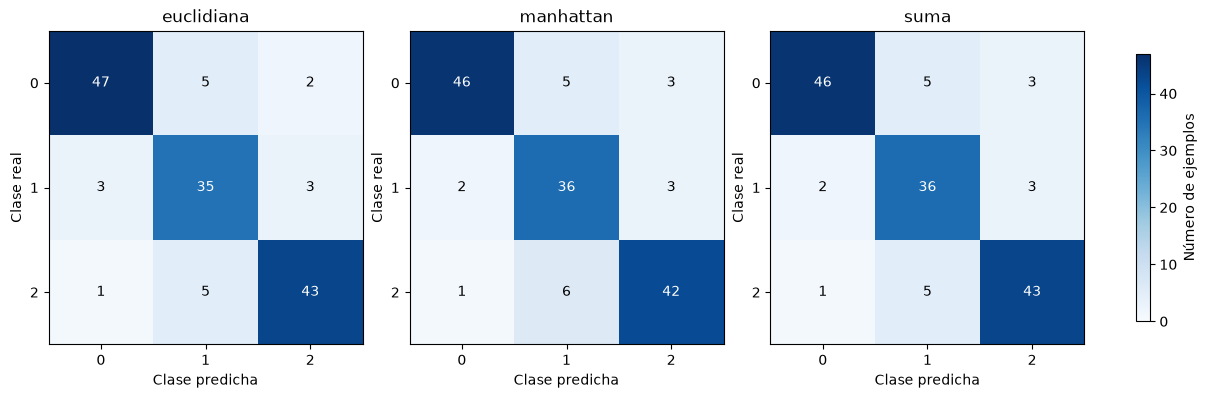

In [10]:
clases = [0, 1, 2]
matrices = [matriz_confusion_manual(y_test, predicciones[(NOMBRE_DETALLE, metrica)], clases)
            for metrica in METRICAS]
maximo = max(valor for matriz in matrices for fila in matriz for valor in fila)
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.7), constrained_layout=True)
for eje, metrica, matriz in zip(ejes, METRICAS, matrices):
    imagen = eje.imshow(matriz, cmap="Blues", vmin=0, vmax=maximo)
    for fila in range(len(clases)):
        for columna in range(len(clases)):
            valor = matriz[fila][columna]
            eje.text(columna, fila, str(valor), ha="center", va="center",
                     color="white" if valor > maximo / 2 else "black")
    eje.set(title=metrica, xlabel="Clase predicha", ylabel="Clase real")
    eje.set_xticks(range(len(clases)), clases)
    eje.set_yticks(range(len(clases)), clases)
fig.colorbar(imagen, ax=ejes, label="Número de ejemplos", shrink=0.85)
plt.show()


## 10. Regiones de decisión

Clasificamos una cuadrícula de puntos usando **el mismo KNN manual**. El fondo indica la clase predicha; los círculos muestran entrenamiento y los triángulos, prueba, coloreados por su clase real. Una cruz negra señala un error en prueba.

Esta celda tarda más porque cada punto de la cuadrícula se compara con todo el entrenamiento. Puedes reducir `RESOLUCION` para acelerar o aumentarla para ver un borde más fino. La cuadrícula es solo una visualización: no se añade al entrenamiento.


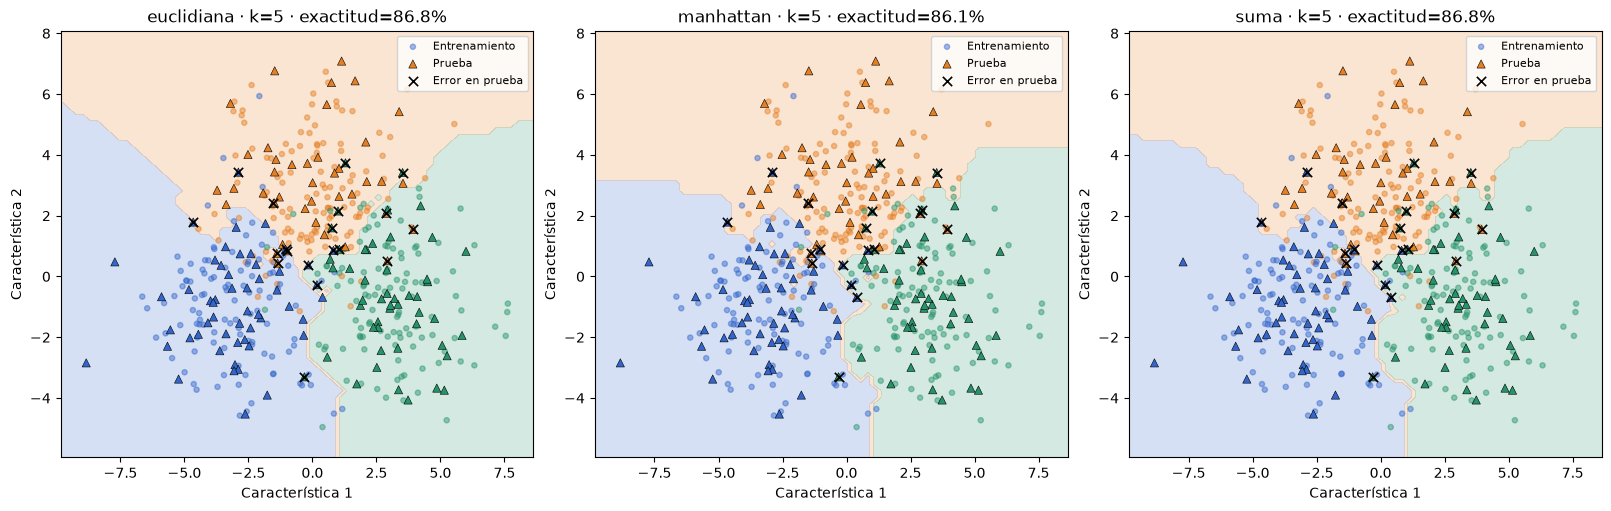

In [11]:
RESOLUCION = 65
X_completo, _ = conjuntos[NOMBRE_DETALLE]
x_min = min(p[0] for p in X_completo) - 1
x_max = max(p[0] for p in X_completo) + 1
y_min = min(p[1] for p in X_completo) - 1
y_max = max(p[1] for p in X_completo) + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, RESOLUCION),
                     np.linspace(y_min, y_max, RESOLUCION))
puntos_cuadricula = [[float(x), float(y)] for x, y in zip(xx.ravel(), yy.ravel())]

fig, ejes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for eje, metrica in zip(ejes, METRICAS):
    modelo = modelos[(NOMBRE_DETALLE, metrica)]
    zz = np.array(modelo.predict(puntos_cuadricula)).reshape(xx.shape)
    eje.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], cmap=COLORES, alpha=0.2)
    eje.scatter([p[0] for p in X_train], [p[1] for p in X_train], c=y_train,
                cmap=COLORES, vmin=-0.5, vmax=2.5, s=14, alpha=0.45, label="Entrenamiento")
    eje.scatter([p[0] for p in X_test], [p[1] for p in X_test], c=y_test,
                cmap=COLORES, vmin=-0.5, vmax=2.5, marker="^", s=35,
                edgecolors="black", linewidths=0.4, label="Prueba")
    y_pred = predicciones[(NOMBRE_DETALLE, metrica)]
    errores = [p for p, real, predicha in zip(X_test, y_test, y_pred) if real != predicha]
    if errores:
        eje.scatter([p[0] for p in errores], [p[1] for p in errores], c="black",
                    marker="x", s=45, linewidths=1.2, label="Error en prueba")
    puntuacion = exactitud(y_test, y_pred)
    eje.set(title=f"{metrica} · k={K} · exactitud={puntuacion:.1%}",
            xlabel="Característica 1", ylabel="Característica 2",
            xlim=(x_min, x_max), ylim=(y_min, y_max))
    eje.legend(loc="upper right", fontsize=8)
plt.show()


## 11. Clasificar puntos nuevos y experimentar

La clase también funciona con más de dos características; las gráficas anteriores están diseñadas para dos. Para probar otro $k$ o distancia, modifica esta celda. Para repetir toda la comparación con otro $k$, cambia `K` en la sección 7 y vuelve a ejecutar las celdas posteriores.


In [12]:
puntos_nuevos = [[-3, -1], [0, 3], [3, -1], [0, 0]]
modelo_nuevo = KNNManual(k=7, metrica="suma").fit(X_train, y_train)
for punto_nuevo, clase in zip(puntos_nuevos, modelo_nuevo.predict(puntos_nuevos)):
    print(f"Punto {str(punto_nuevo):>10} -> clase predicha {clase}")


Punto   [-3, -1] -> clase predicha 0
Punto     [0, 3] -> clase predicha 1
Punto    [3, -1] -> clase predicha 2
Punto     [0, 0] -> clase predicha 2


## Qué observar

- **Elección de $k$:** valores pequeños producen fronteras más sensibles al ruido; valores grandes suavizan las decisiones y pueden borrar detalles útiles.
- **Distancia:** cada métrica puede ordenar de otra forma los mismos vecinos. Si coinciden las predicciones o las exactitudes en un conjunto, eso no implica que las métricas sean equivalentes.
- **Escalas:** una característica con valores mucho mayores puede dominar las tres distancias. Aquí conservamos las unidades generadas para observar su geometría. Si estandarizas en otro problema, calcula la media y la desviación únicamente con entrenamiento y aplica esos mismos parámetros a prueba y a puntos nuevos.
- **Coste:** con $n$ ejemplos de entrenamiento y $p$ características, esta implementación necesita $O(np+n\log n)$ por consulta: calcula todas las distancias y ordena los $n$ resultados. Guardar el entrenamiento requiere $O(np)$ de memoria.
- **Límite del experimento:** `make_blobs` genera grupos sintéticos; un resultado alto aquí no garantiza un resultado alto con datos reales.

### Ejercicios

1. Repite con $k=1$, $k=5$ y $k=15$ y observa las fronteras. Para seleccionar un valor, añade validación dentro del entrenamiento.
2. Aumenta `cluster_std` y observa los errores en la matriz de confusión.
3. Multiplica una característica por 10 y estudia cómo cambia la geometría de los vecinos.
4. Genera datos con `n_features=4` y centros de cuatro coordenadas, y reutiliza `KNNManual` sin cambiar su implementación. Evalúa con exactitud y una matriz de confusión; omite las gráficas bidimensionales.
